In [1]:
#Importing libraries 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

In [2]:
#Creating sample dataset
X, true_labels = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

print("Dataset shape:", X.shape)

Dataset shape: (300, 2)


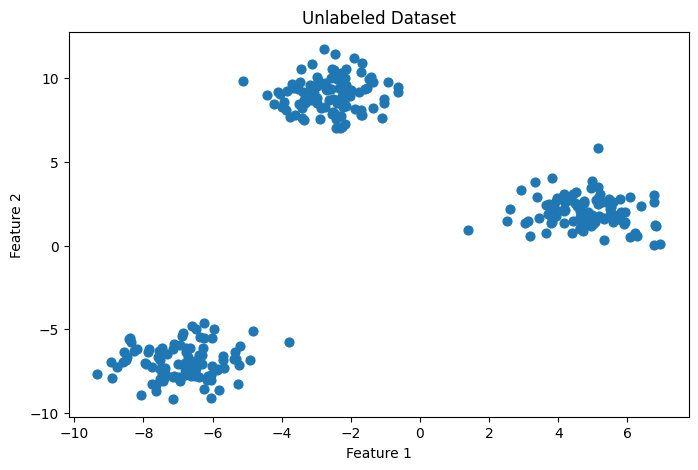

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=40
)

plt.title("Unlabeled Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [4]:
#Training K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans.fit(X)

cluster_labels = kmeans.labels_

print("Cluster assignments:")
print(cluster_labels[:20])

Cluster assignments:
[1 1 0 2 1 2 0 2 0 0 0 2 0 0 1 0 1 2 0 0]


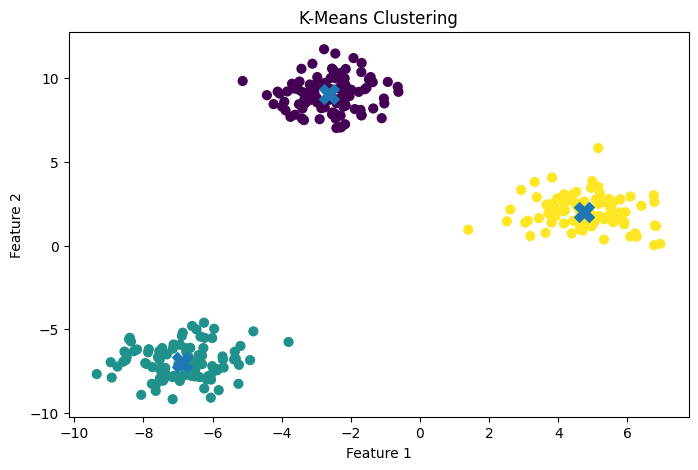

In [5]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=cluster_labels,
    s=40
)

centroids = kmeans.cluster_centers_

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [6]:
inertia_values = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X)

    inertia_values.append(model.inertia_)

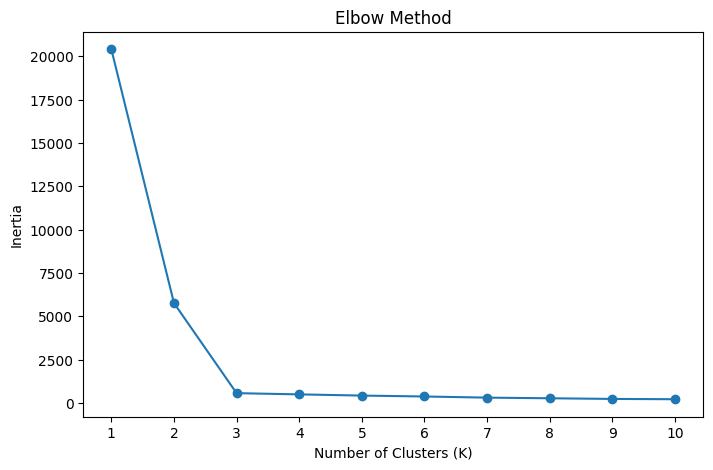

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.show()

In [8]:
#Evaluate clusters using Silhouette Score
score = silhouette_score(X, cluster_labels)

print("Silhouette Score:", score)

Silhouette Score: 0.8480303059596955


In [9]:
for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    print(f"K = {k}, Silhouette Score = {score:.3f}")

K = 2, Silhouette Score = 0.705
K = 3, Silhouette Score = 0.848
K = 4, Silhouette Score = 0.664
K = 5, Silhouette Score = 0.490
K = 6, Silhouette Score = 0.517
K = 7, Silhouette Score = 0.358


In [10]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original feature means:", X.mean(axis=0))
print("Scaled feature means:", X_scaled.mean(axis=0))

Original feature means: [-1.59000036  1.35672664]
Scaled feature means: [-5.10702591e-17  4.14483263e-17]


In [11]:
#Training K Means on the scaled data
scaled_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

scaled_labels = scaled_kmeans.fit_predict(X_scaled)

print(
    "Scaled silhouette score:",
    silhouette_score(X_scaled, scaled_labels)
)

Scaled silhouette score: 0.8482330810203894
